# 5 mmol Thesis-Style Static XAS Diagnostics

Thin notebook for thesis-style static XAS/GMD baseline checks.  The analysis code lives in `analysis/scripts/static_xas_thesis_diagnostics.py`; this notebook only sets paths, analysis parameters, and plot zoom limits.

Main observable:

`OD(E) = log10(sum(GMD) / sum(integrated VLS))`

This follows the thesis liquid-glycine section where GMD is used as the incident-flux proxy and summed detector counts are used as transmitted intensity.

In [1]:
from __future__ import annotations

import os
import sys
import tempfile
from pathlib import Path

mpl_cache = Path(tempfile.gettempdir()) / "glycine26-matplotlib-cache"
mpl_cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_cache))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160})


def find_repo_root(start: Path) -> Path:
    for parent in [start, *start.parents]:
        if (parent / "analysis" / "scripts" / "static_xas_thesis_diagnostics.py").exists():
            return parent
    raise RuntimeError("Could not find repo root")


REPO_ROOT = find_repo_root(Path.cwd())
SCRIPTS_DIR = REPO_ROOT / "analysis" / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import config as path_config
import static_xas_thesis_diagnostics as txd

REPO_ROOT

PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26')

## Analysis Parameters

For thesis-style plots, the default GMD bins are quantile bins so each curve has comparable statistics.  Change `GMD_BIN_MODE` to `"fixed"` to use the familiar 0-10 uJ, 1 uJ-wide bins.

In [2]:
INPUT_H5 = Path(path_config.COMBINED_DIR).parent / "xas_static" / "run58794_static_xas.h5"

GMD_BIN_MODE = "quantile"  # "quantile" for thesis-style equal-stat bins, "fixed" for 0-10 uJ bins
N_GMD_BINS = 5
FIXED_GMD_EDGES = np.arange(0.0, 11.0, 1.0)

CONFIG = txd.ThesisXASConfig(
    gmd_bin_mode=GMD_BIN_MODE,
    n_gmd_bins=N_GMD_BINS,
    fixed_gmd_edges=tuple(FIXED_GMD_EDGES),
    gmd_min_threshold=None,
    gmd_max_threshold=10.0,
    vls_intensity_threshold=1000.0,
    reject_double_peaks=False,
    center_method="com",
    center_half_window=5,
    selected_energies_ev=(273.5, 274.0, 275.0, 275.6, 277.1, 283.0, 284.0),
    selected_max_shots_per_energy=20_000,
    chunk_size=20_000,
    edge_pixel_count=20,
    min_shots_for_interpretation=200,
)

INPUT_H5

PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_static_xas.h5')

## Plot Zoom Parameters

These are the main knobs for interactive inspection.  Use `None` to autoscale.

In [3]:
FULL_XLIM = (271.0, 286.0)
LOW_ENERGY_XLIM = (273.5, 277.2)
EDGE_XLIM = (281.5, 284.2)

OD_YLIM = None
LOW_OD_YLIM = None
EDGE_OD_YLIM = None
SIMPLE_RATIO_YLIM = None

CORR_XLIM = (0.0, 10.0)
CORR_YLIM = None

PIXEL_XLIM = None
SPECTRUM_YLIM = None

CORRELATION_ENERGIES_EV = (273.5, 275.6, 284.0)
VLS_STAT_ENERGIES_EV = (273.5, 274.0, 275.0, 275.6, 277.1, 283.0, 284.0)
SHAPE_BIN_ENERGY_EV = 275.6

## Compute Diagnostics

This is the only heavy cell.  It streams the H5 in chunks, computes the GMD/VLS correlation fits, chooses GMD bins, and aggregates all notebook plots.

In [4]:
diag = txd.compute_thesis_diagnostics(INPUT_H5, CONFIG)

print(f"input H5        : {INPUT_H5}")
print(f"nominal energies: {diag.energies.size}, {diag.energies[0]:.2f}..{diag.energies[-1]:.2f} eV")
print(f"GMD bin mode    : {CONFIG.gmd_bin_mode}")
print(f"GMD edges       : {np.array2string(diag.gmd_edges, precision=3)}")
print(f"GMD labels      : {diag.gmd_labels}")
print(f"accepted shots  : {int(np.sum(diag.filter_counts['kept'])):,}")

input H5        : /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_static_xas.h5
nominal energies: 31, 286.00..271.00 eV
GMD bin mode    : quantile
GMD edges       : [ 0.036  2.76   3.658  4.69   6.167 10.   ]
GMD labels      : ['mean 2.1 uJ', 'mean 3.2 uJ', 'mean 4.2 uJ', 'mean 5.4 uJ', 'mean 7.6 uJ']
accepted shots  : 556,380


## 1. Filtering And GMD Statistics

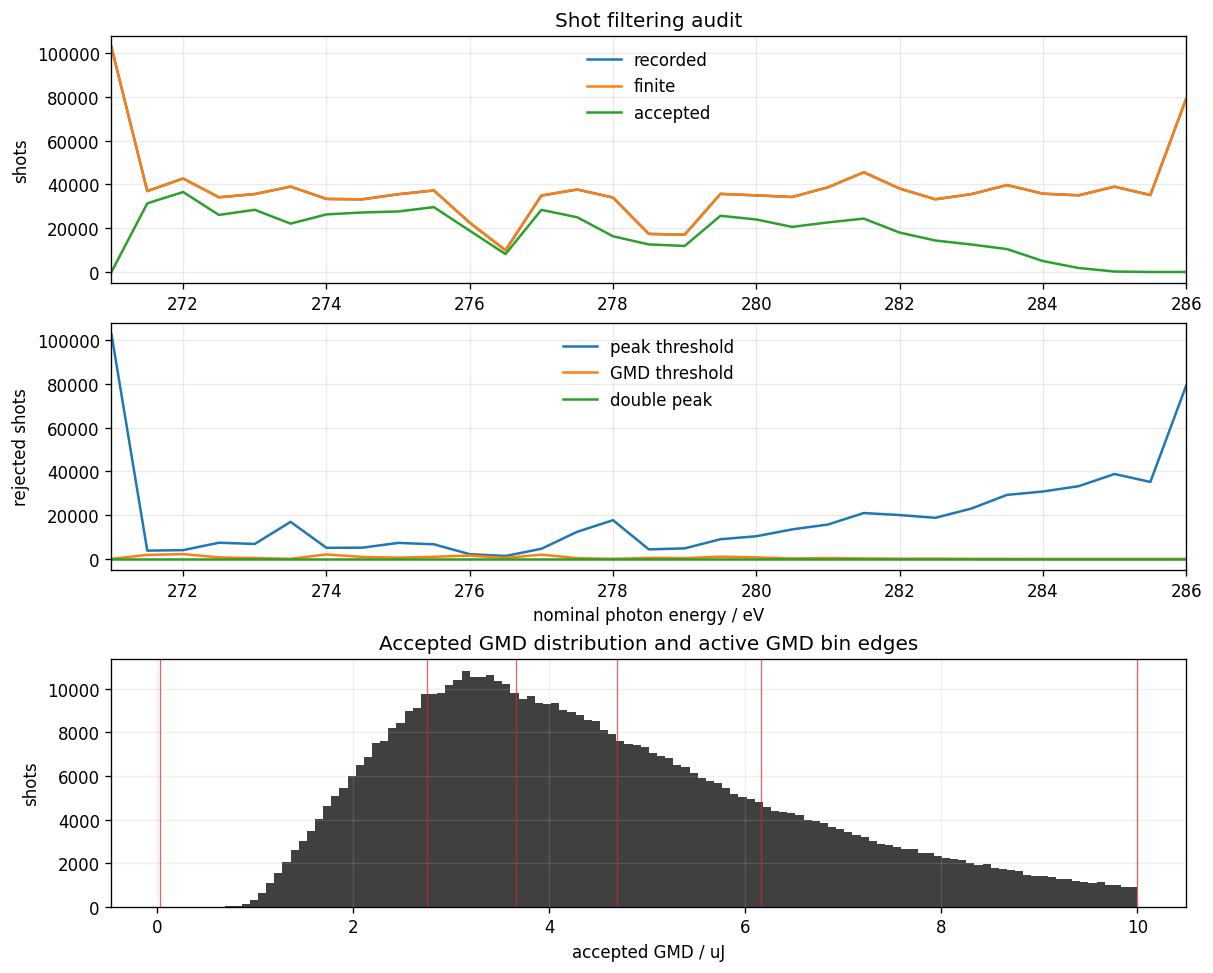

In [5]:
txd.plot_filter_audit(diag, xlim=FULL_XLIM)
plt.show()

## 2. Thesis Figure VI.15 Equivalent: GMD vs Transmitted VLS

The intercept is the thesis-style dark-count/background check.  A non-zero intercept means the denominator has an additive component before any physical interpretation.

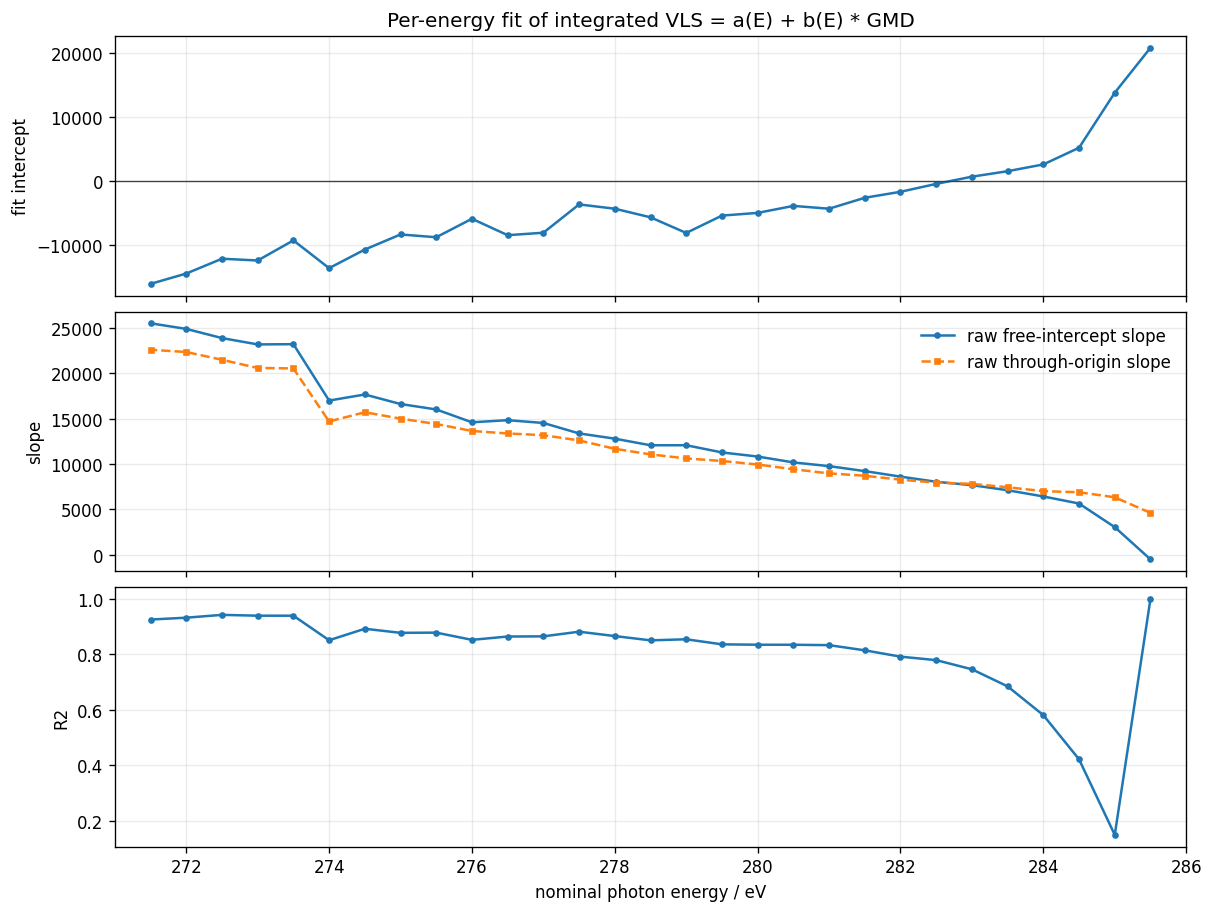

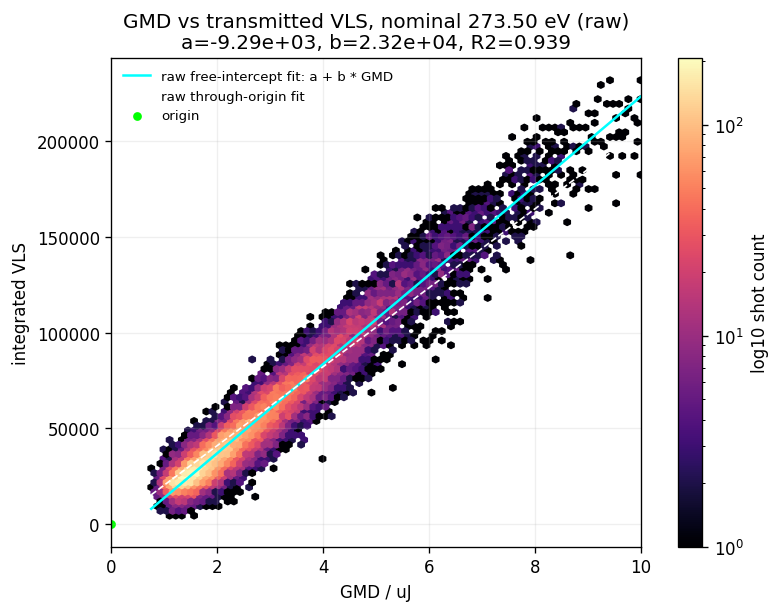

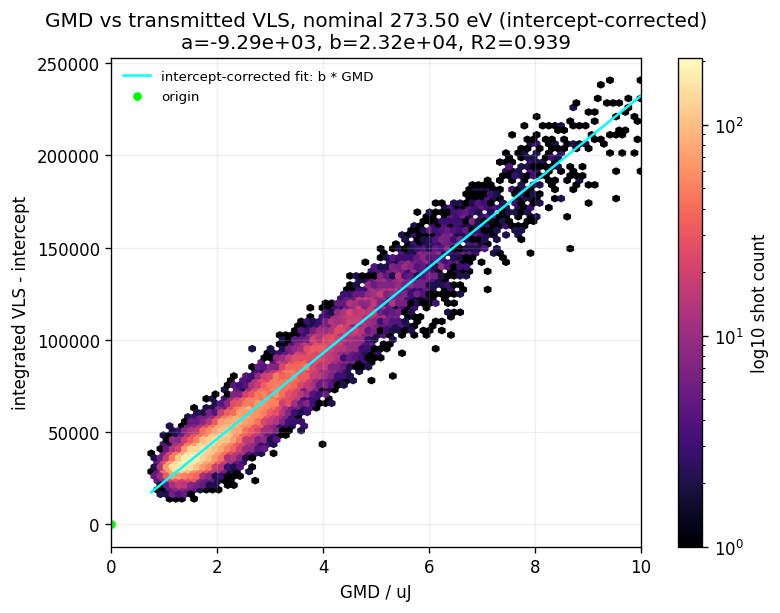

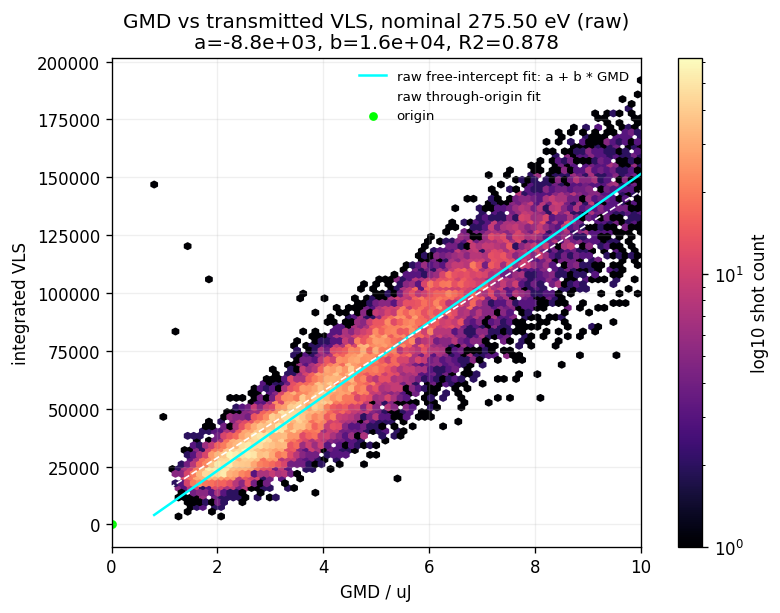

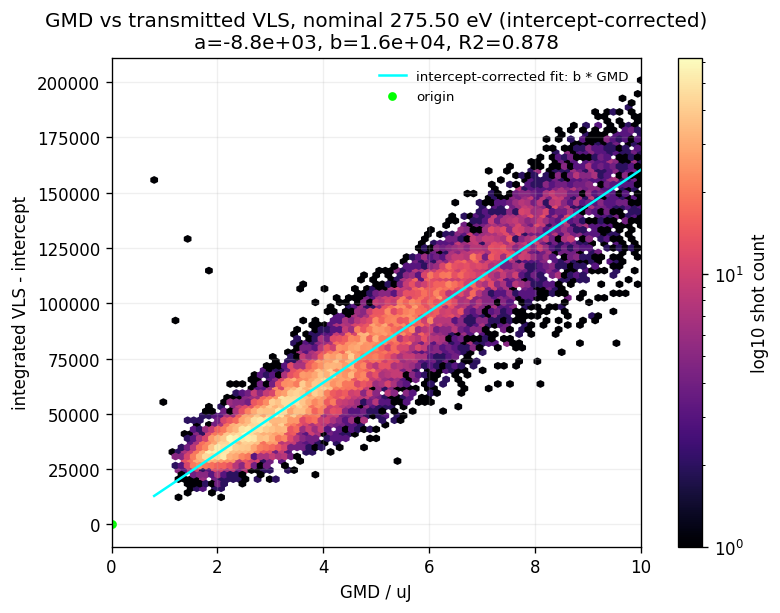

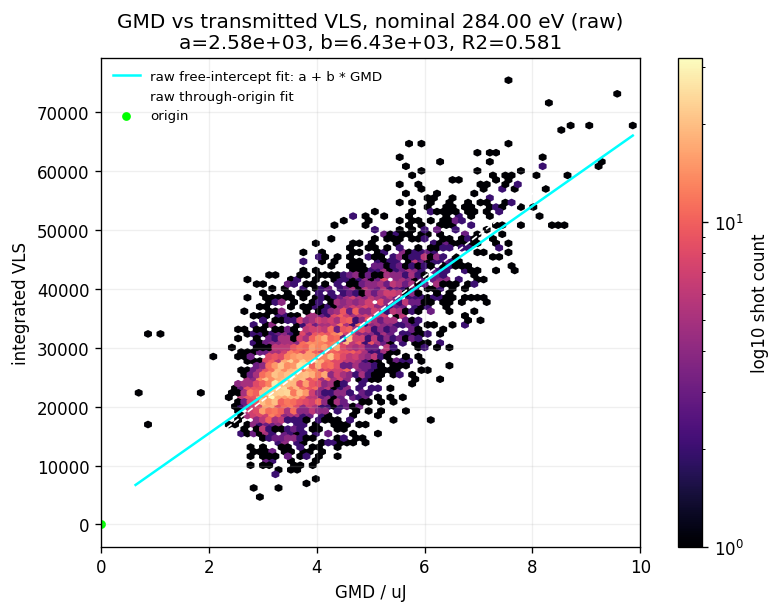

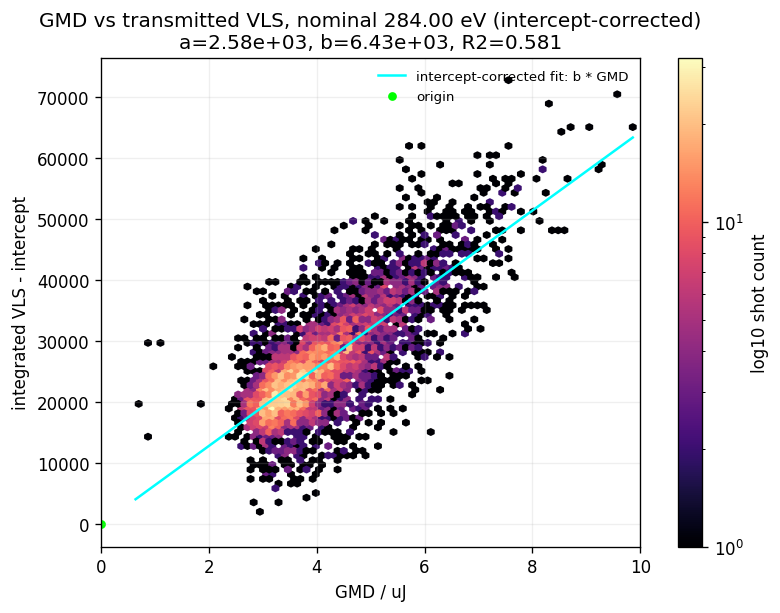

In [6]:
txd.plot_fit_summary(diag, xlim=FULL_XLIM)
plt.show()

for energy_ev in CORRELATION_ENERGIES_EV:
    txd.plot_gmd_vls_correlation(diag, energy_ev, corrected=False, xlim=CORR_XLIM, ylim=CORR_YLIM)
    plt.show()
    txd.plot_gmd_vls_correlation(diag, energy_ev, corrected=True, xlim=CORR_XLIM, ylim=CORR_YLIM)
    plt.show()

## 3. Thesis Figure VI.16 Equivalent: Non-GMD-Resolved OD

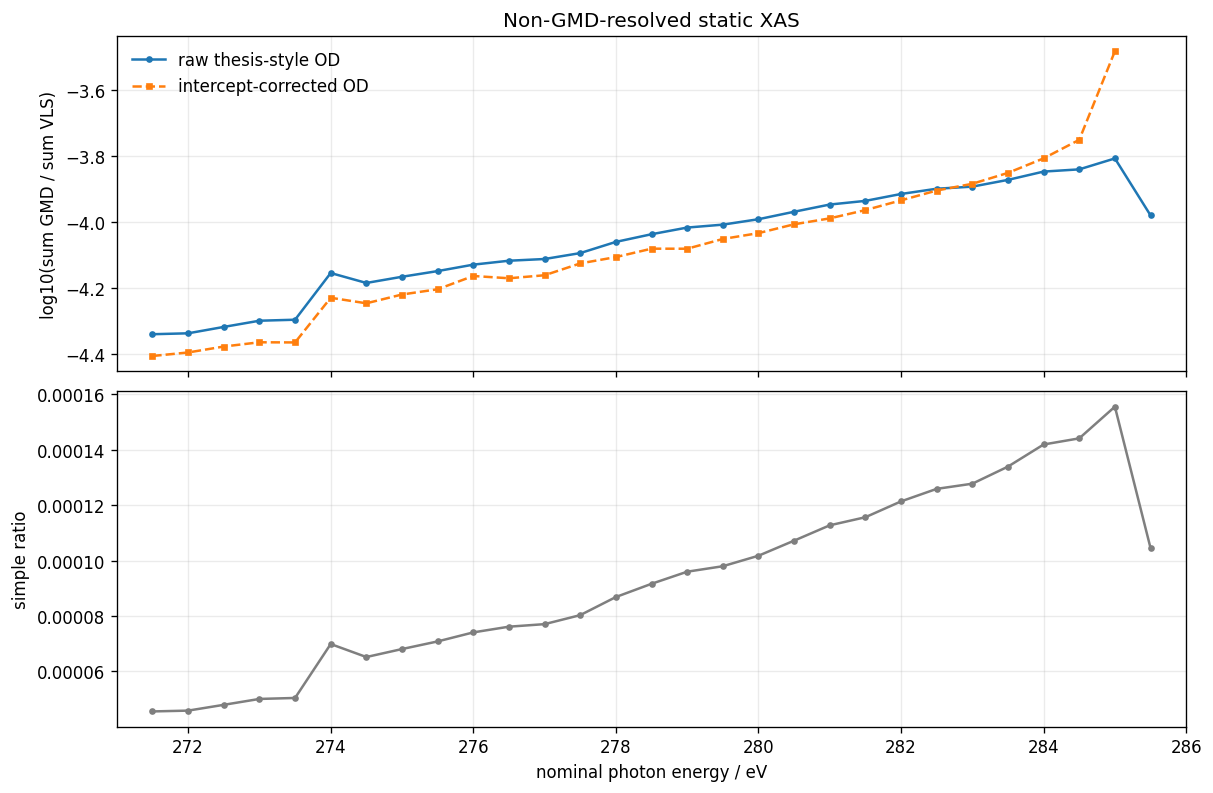

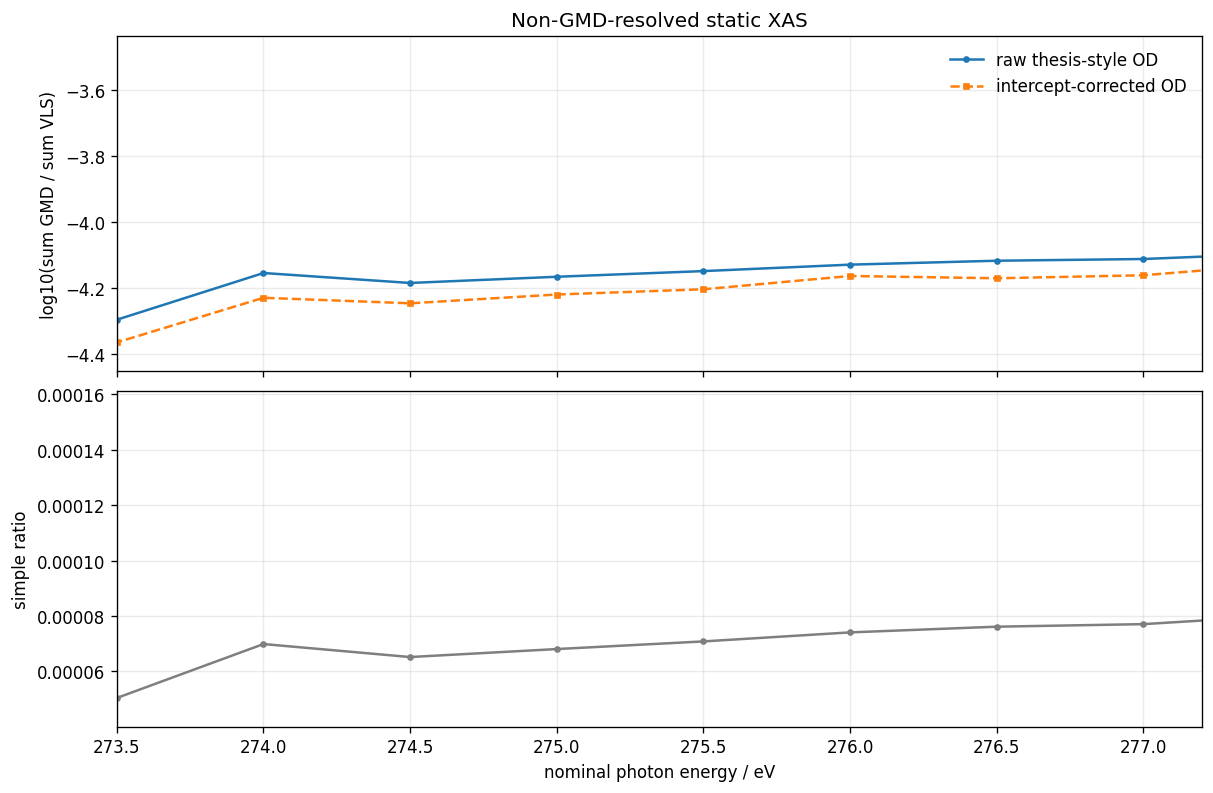

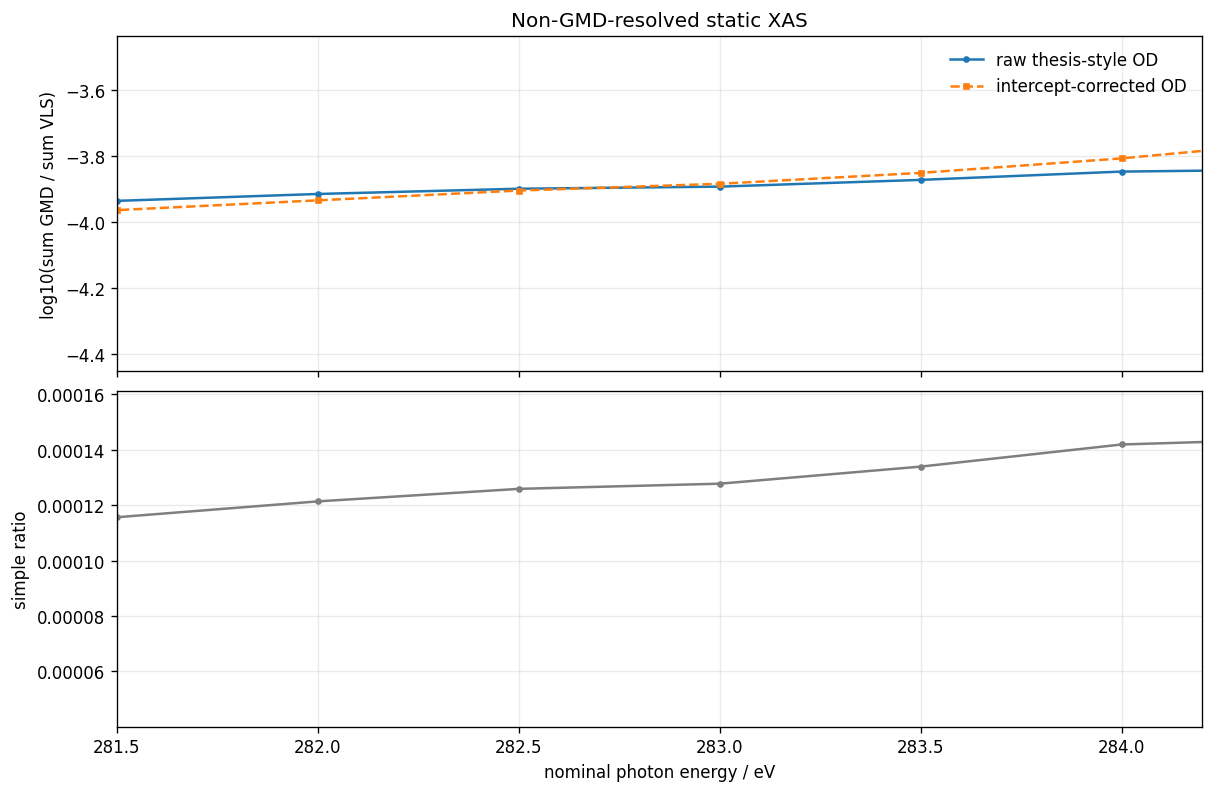

In [7]:
txd.plot_total_od(diag, xlim=FULL_XLIM, od_ylim=OD_YLIM, ratio_ylim=SIMPLE_RATIO_YLIM)
plt.show()

txd.plot_total_od(diag, xlim=LOW_ENERGY_XLIM, od_ylim=LOW_OD_YLIM, ratio_ylim=SIMPLE_RATIO_YLIM)
plt.show()

txd.plot_total_od(diag, xlim=EDGE_XLIM, od_ylim=EDGE_OD_YLIM, ratio_ylim=SIMPLE_RATIO_YLIM)
plt.show()

## 4. Thesis Figure VI.17 Equivalent: GMD-Binned OD

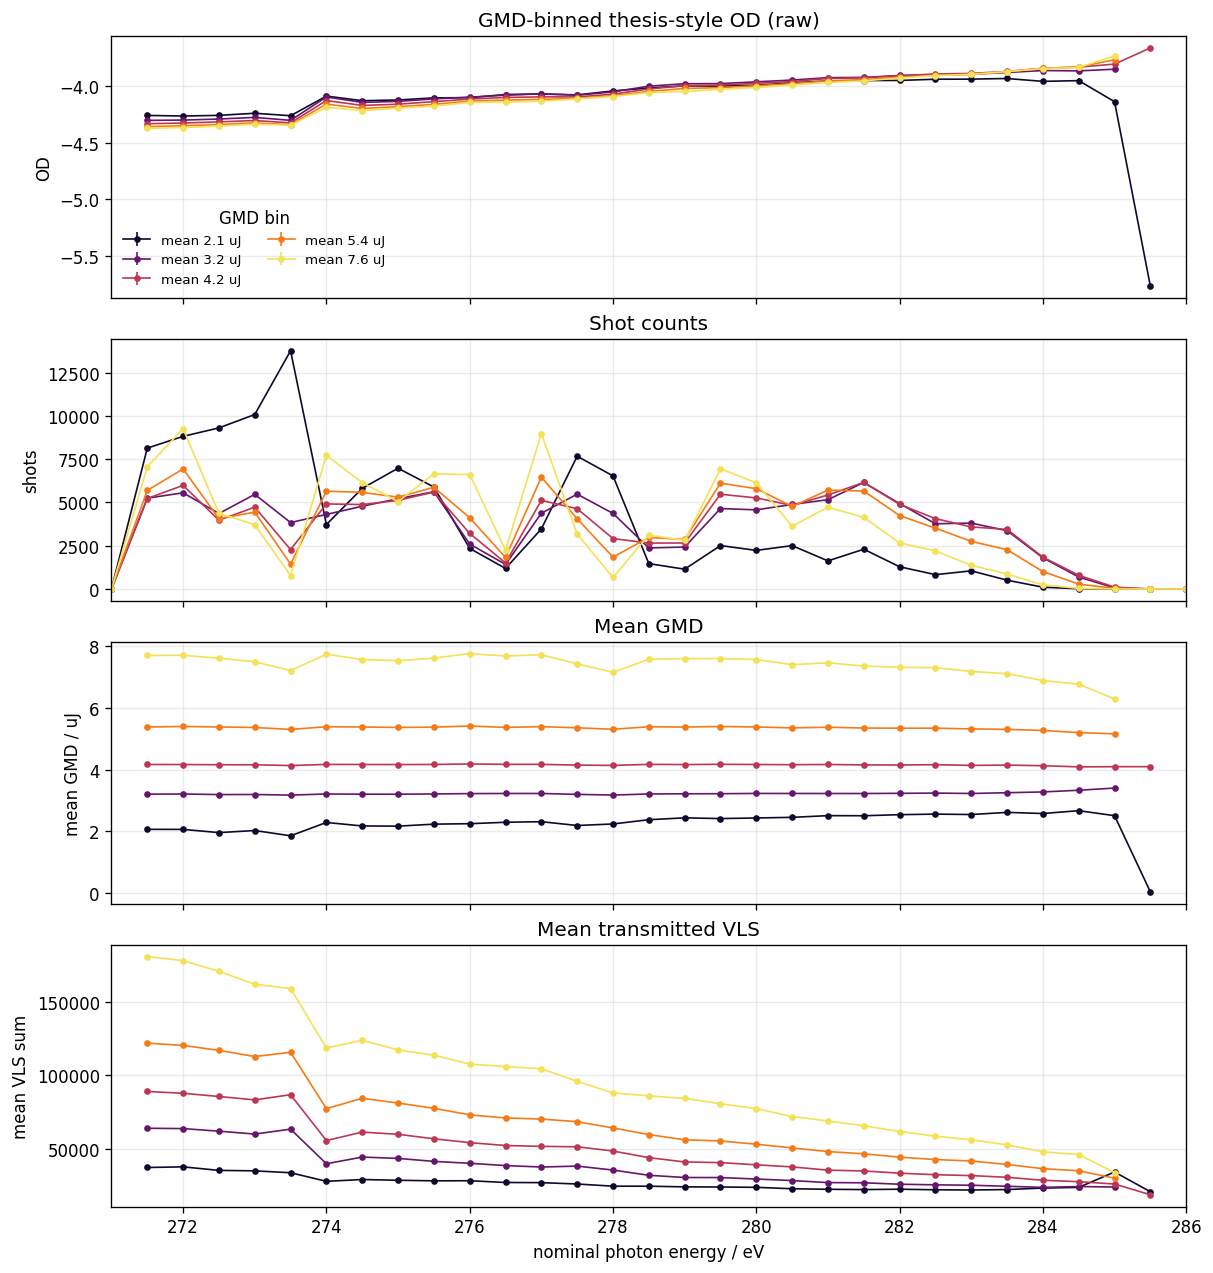

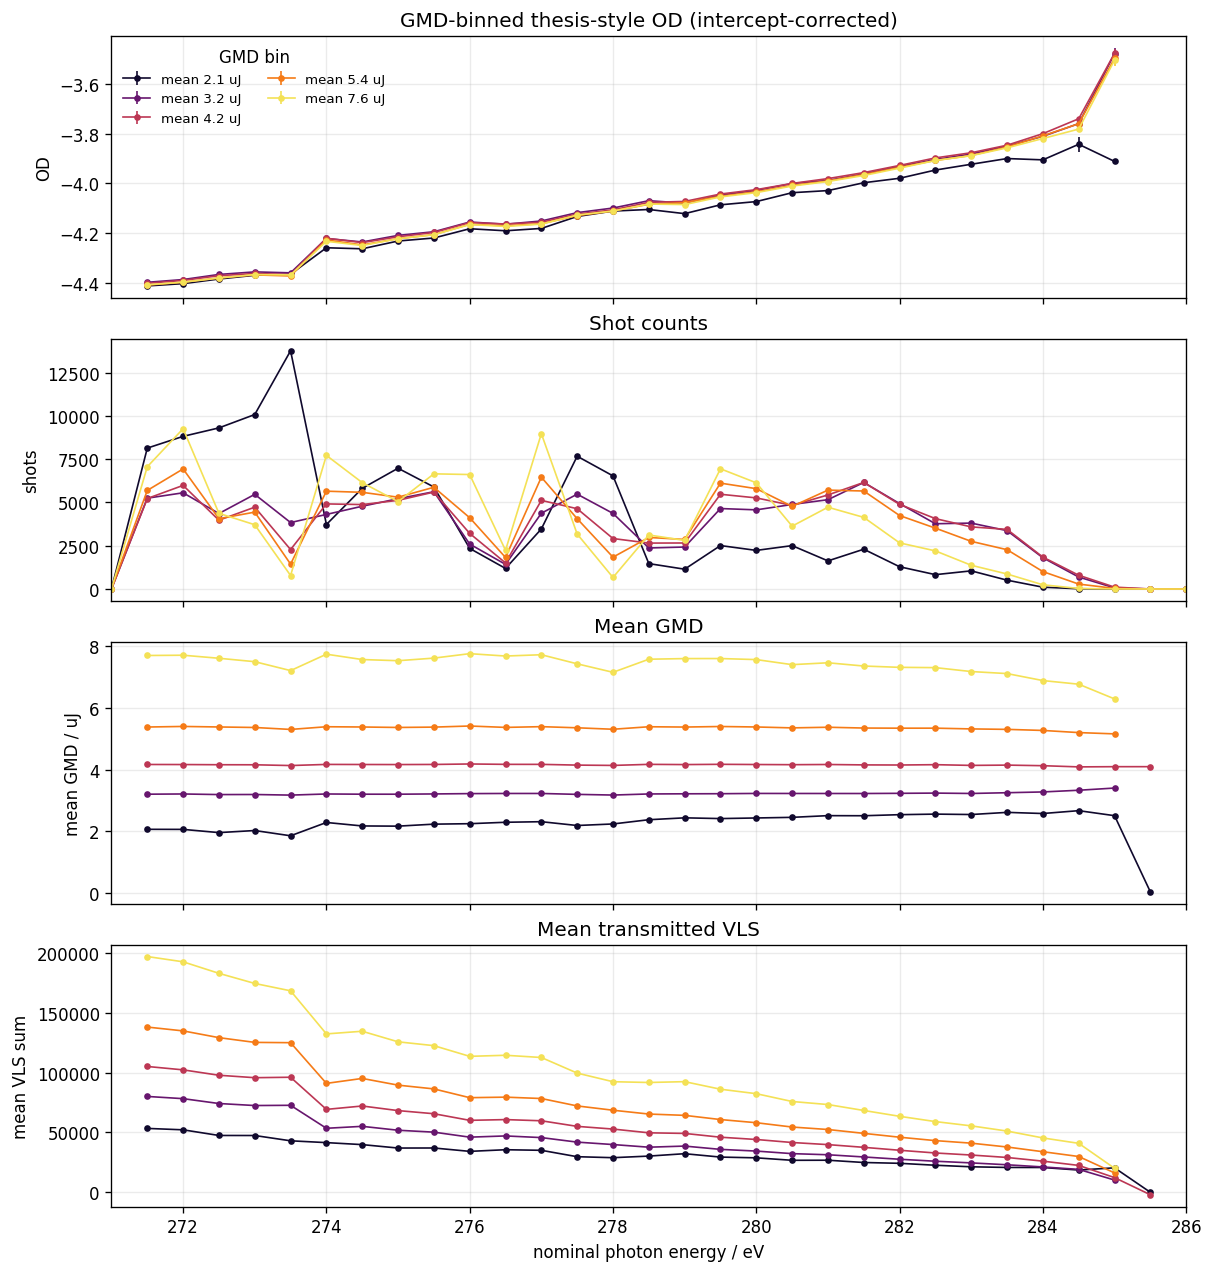

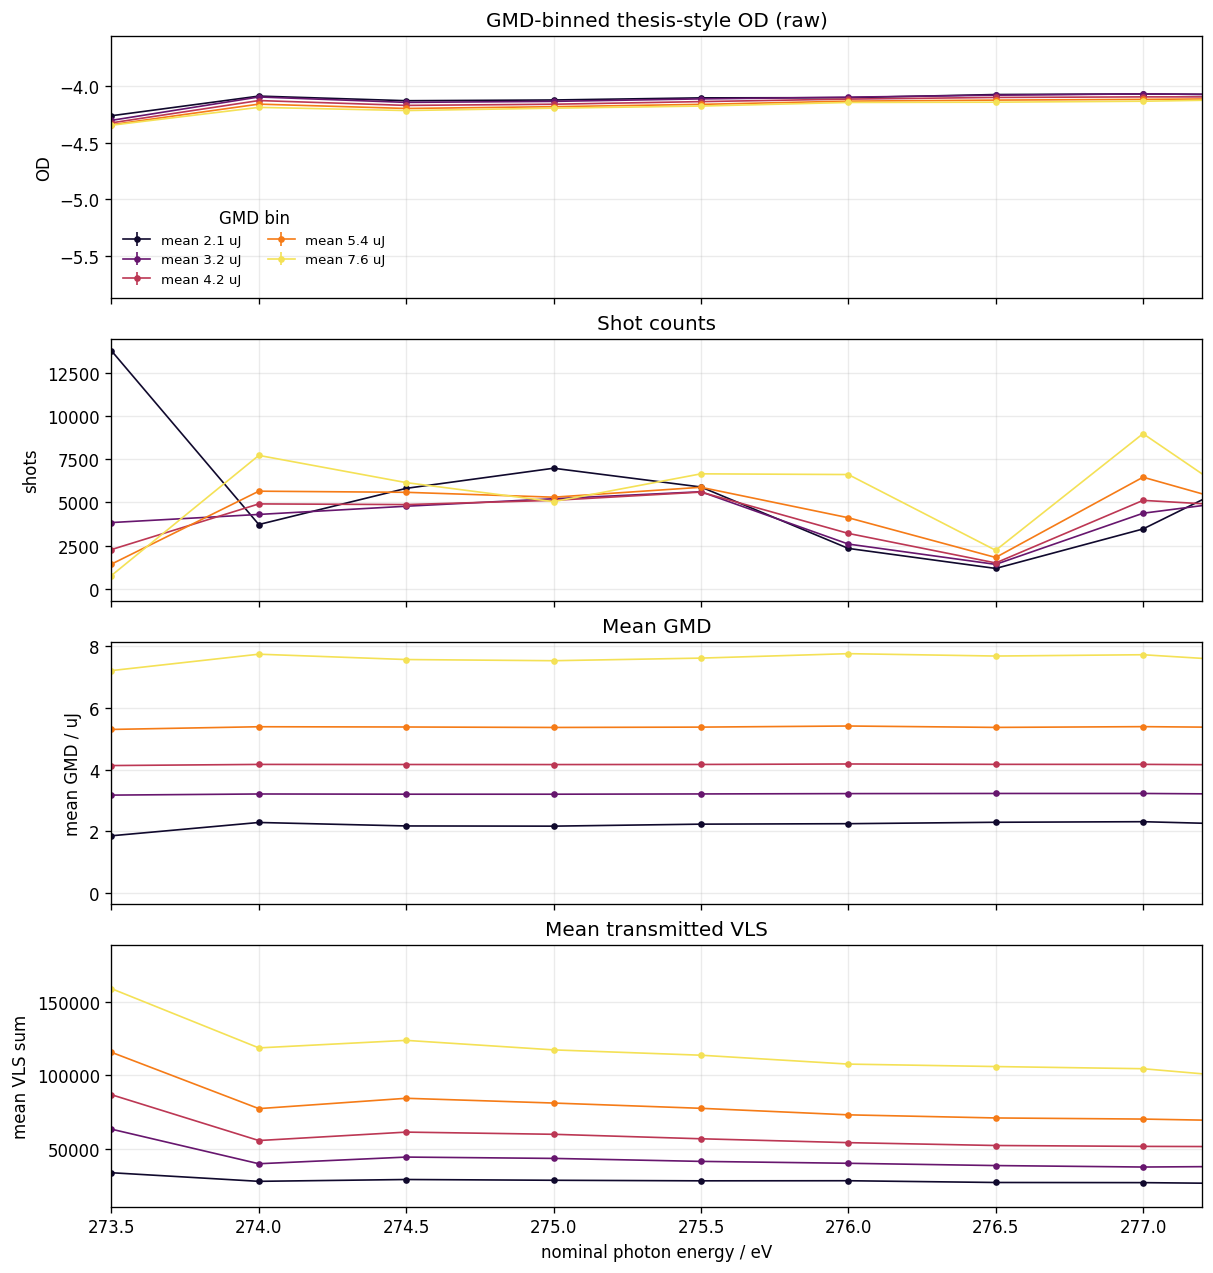

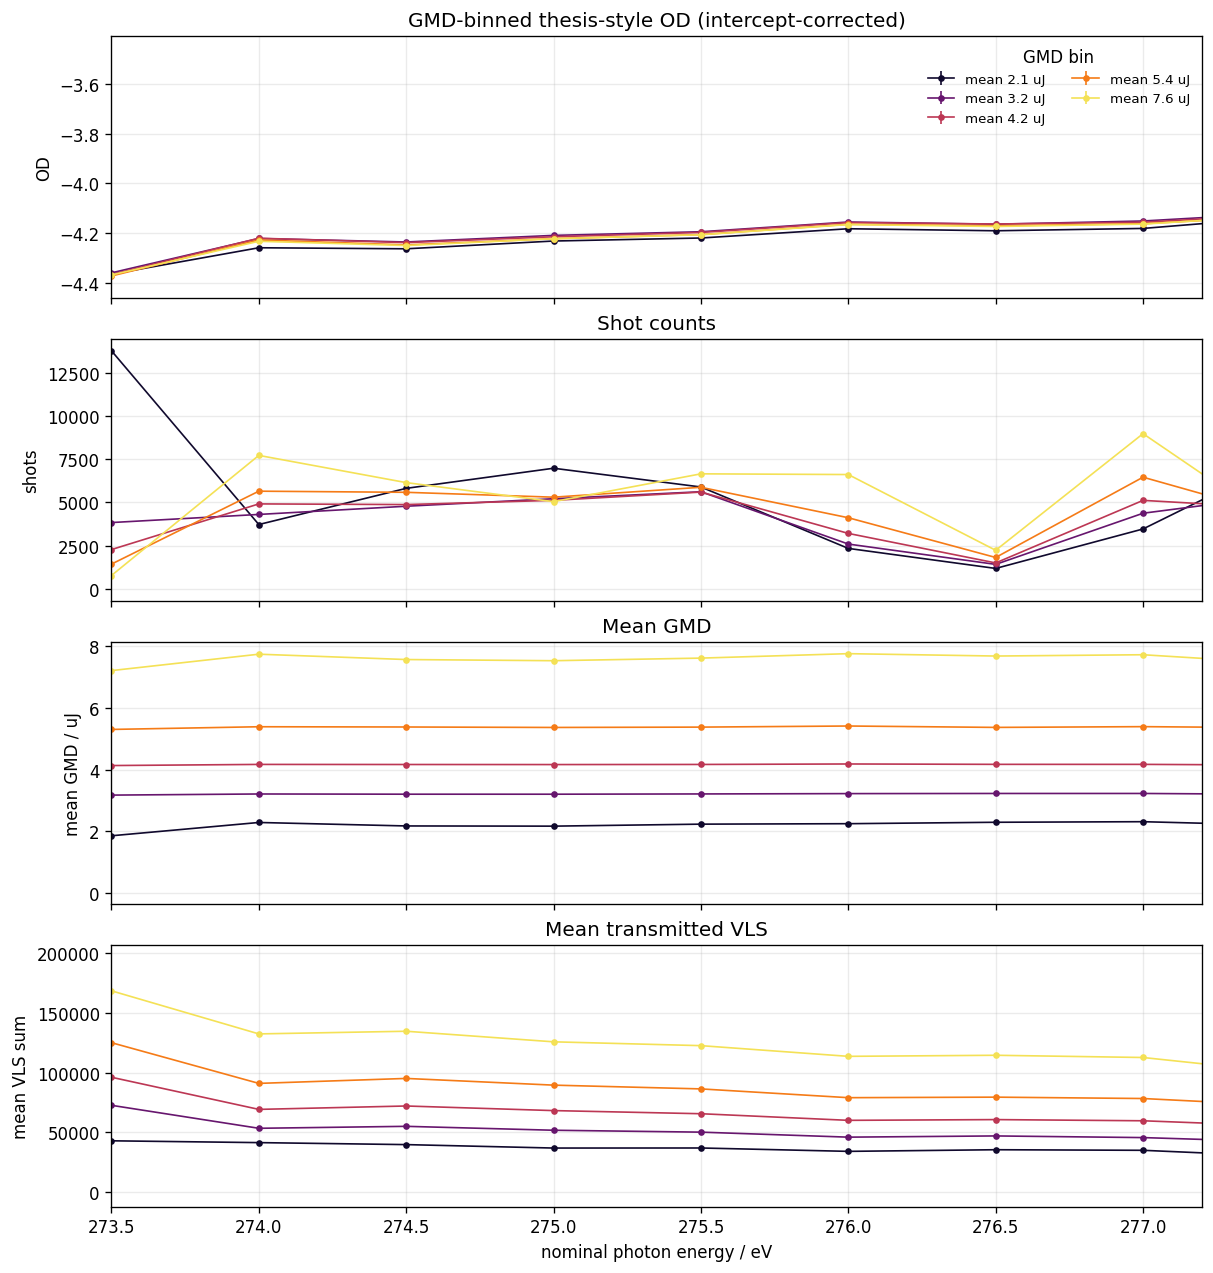

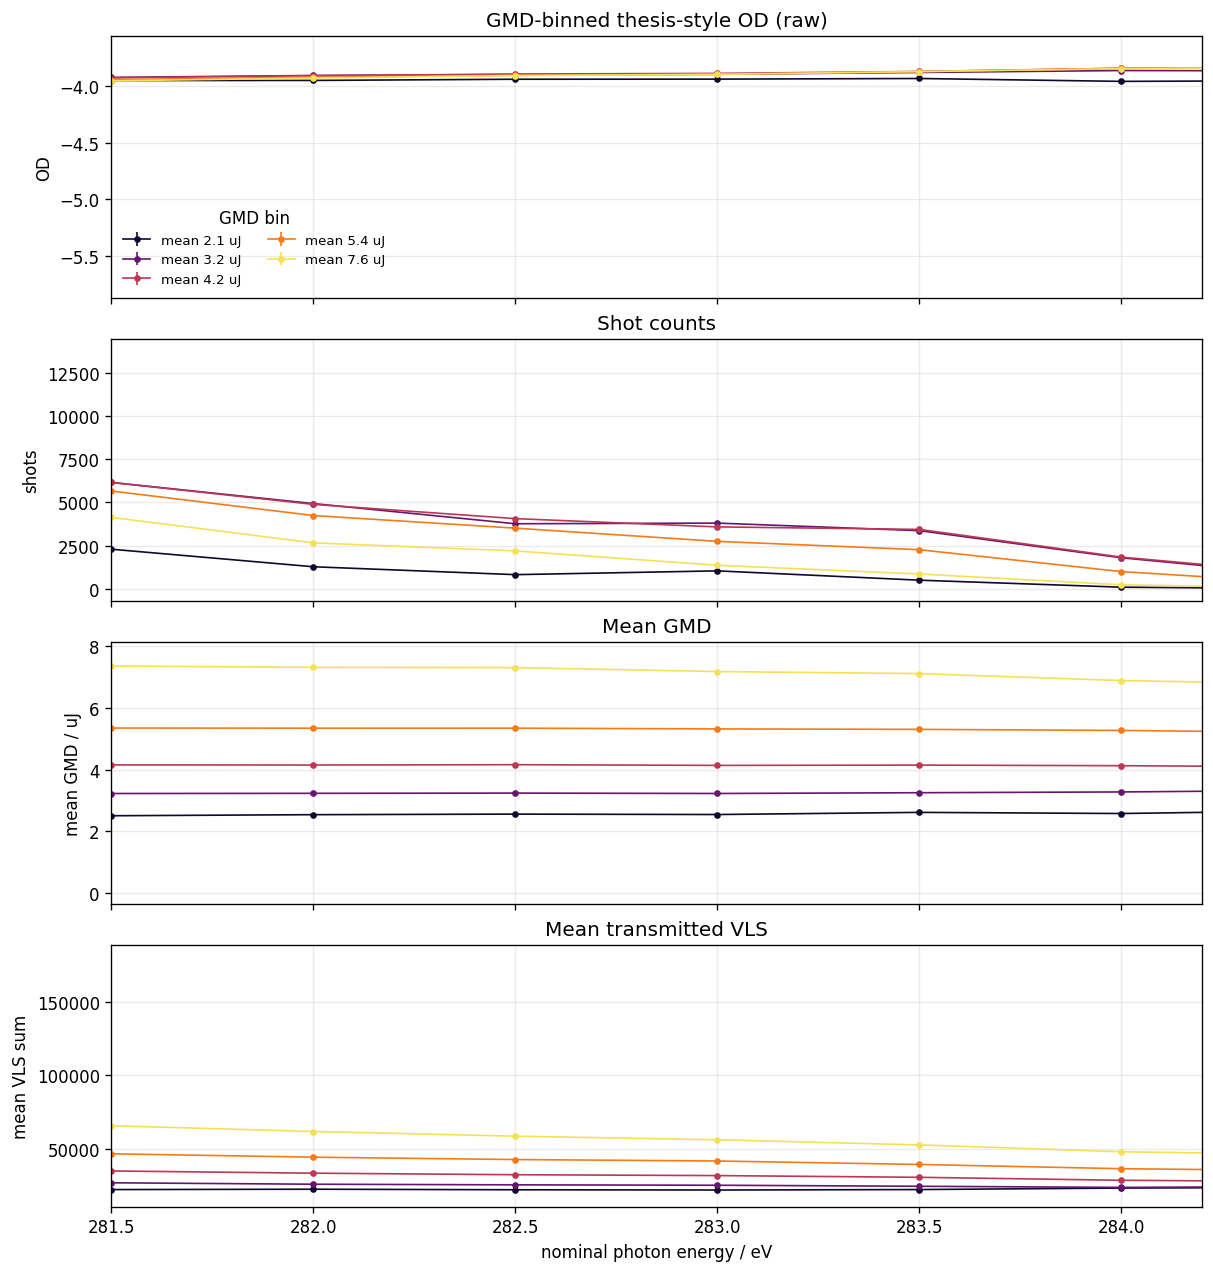

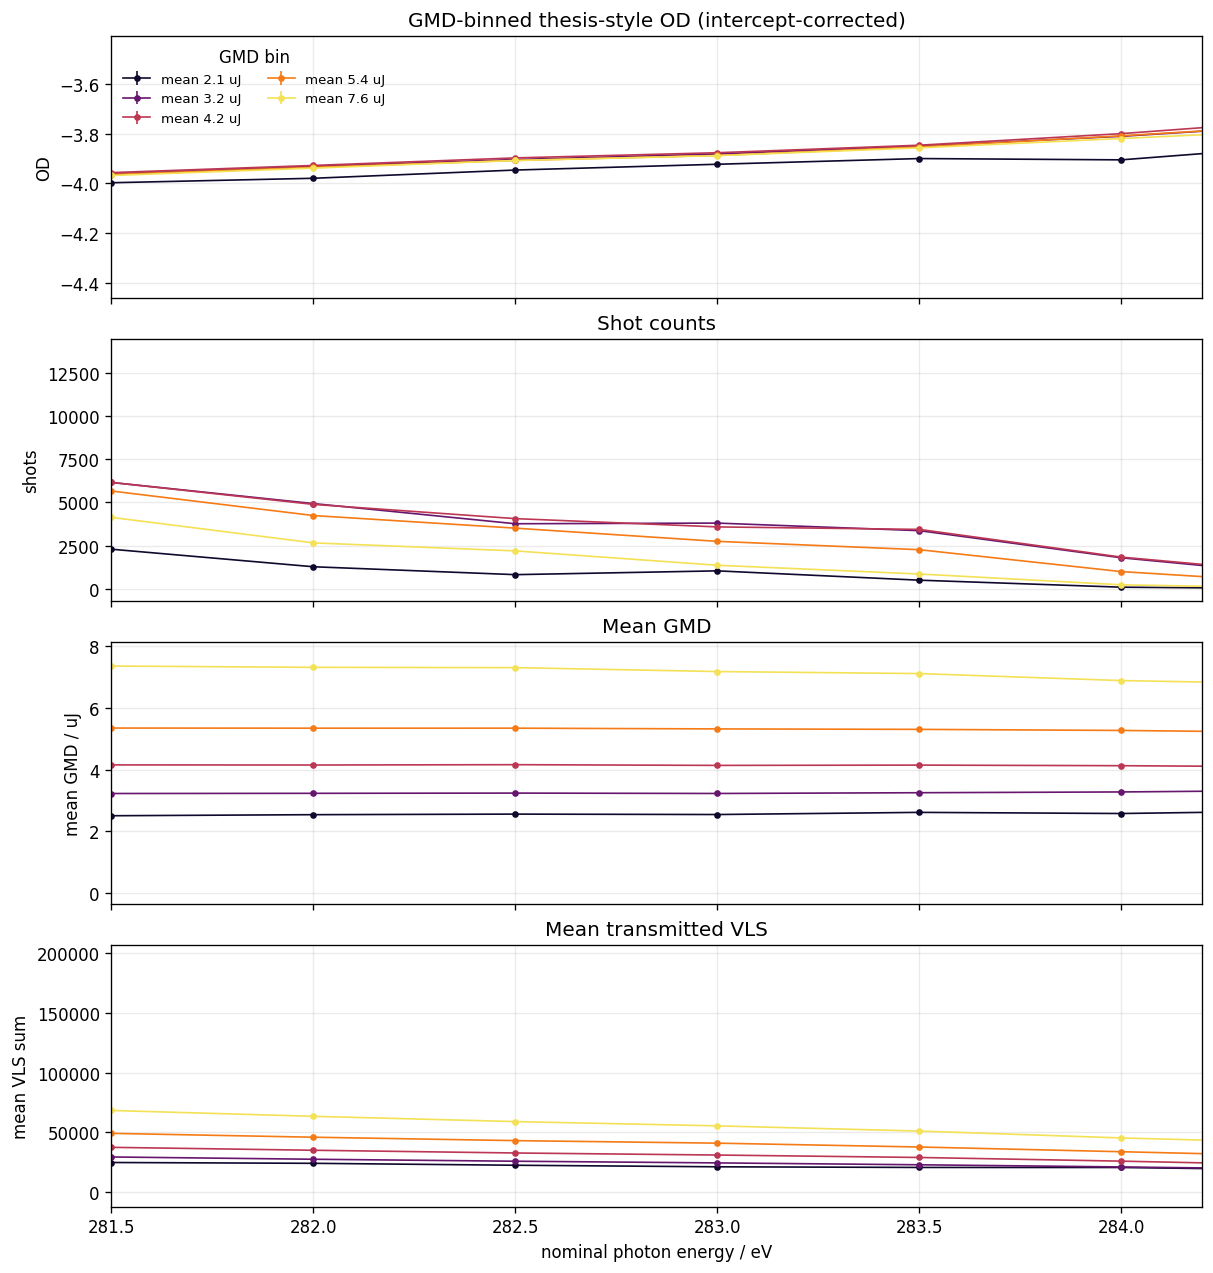

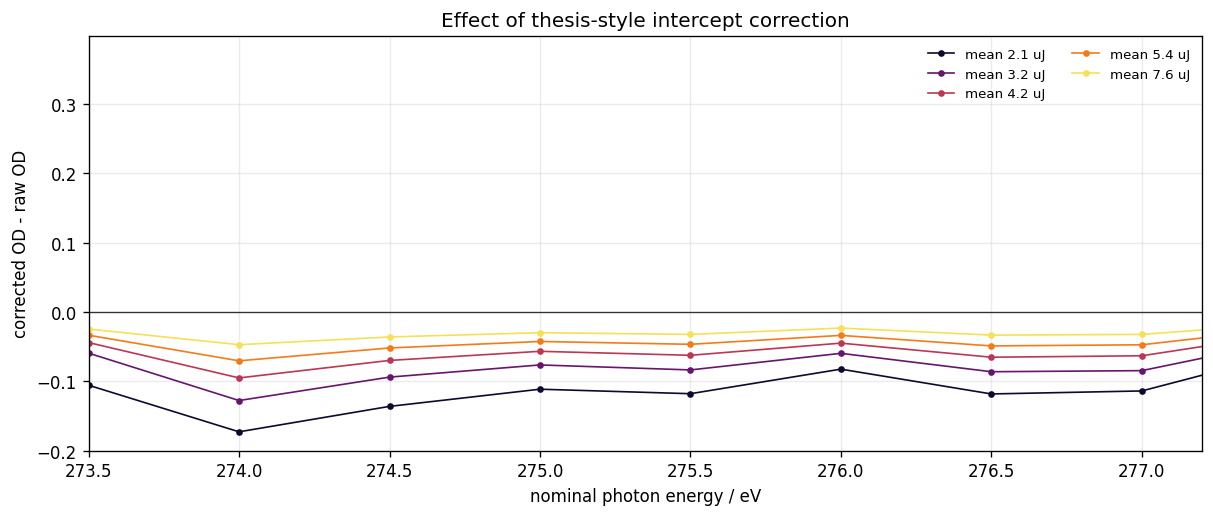

In [8]:
for xlim, ylim in [(FULL_XLIM, OD_YLIM), (LOW_ENERGY_XLIM, LOW_OD_YLIM), (EDGE_XLIM, EDGE_OD_YLIM)]:
    txd.plot_gmd_binned_od(diag, corrected=False, xlim=xlim, ylim=ylim)
    plt.show()
    txd.plot_gmd_binned_od(diag, corrected=True, xlim=xlim, ylim=ylim)
    plt.show()

txd.plot_correction_effect(diag, xlim=LOW_ENERGY_XLIM)
plt.show()

## 5. VLS Statistics Within GMD Bins

These plots decide whether GMD-bin offsets are detector/background offsets, denominator effects, or VLS shape changes.

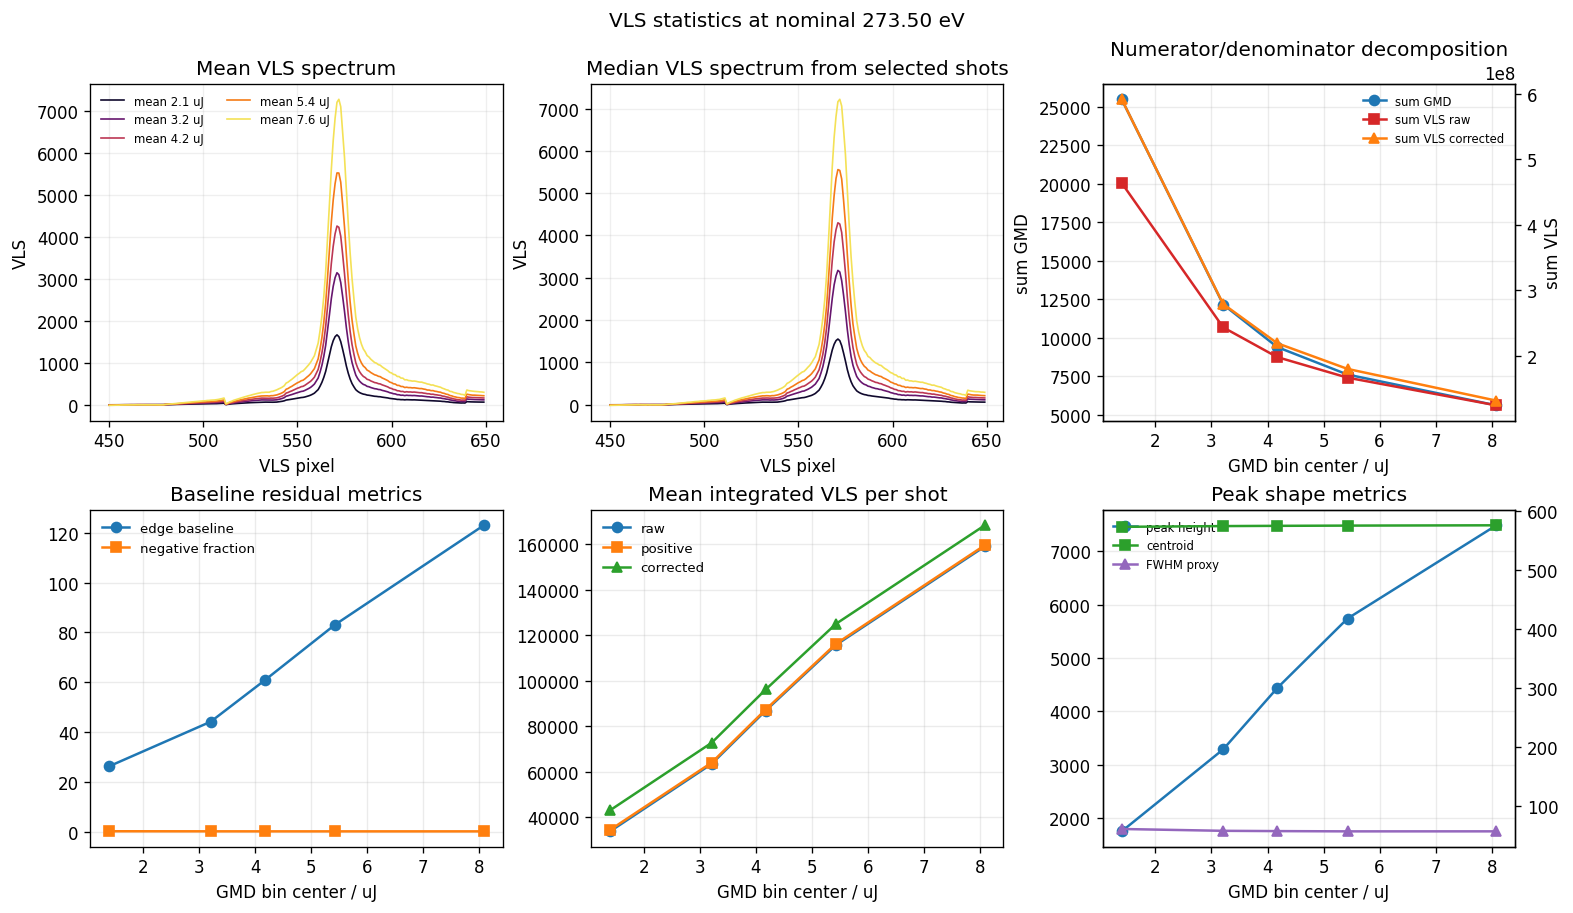

Interpretation metrics near nominal 273.50 eV
metric                         range/span
raw OD span                    0.0839706
corrected OD span              0.0125574
edge baseline span             96.7488
centroid span                  2.60122
FWHM proxy span                4.02284
mean GMD span                  5.35156
mean VLS raw span              125325



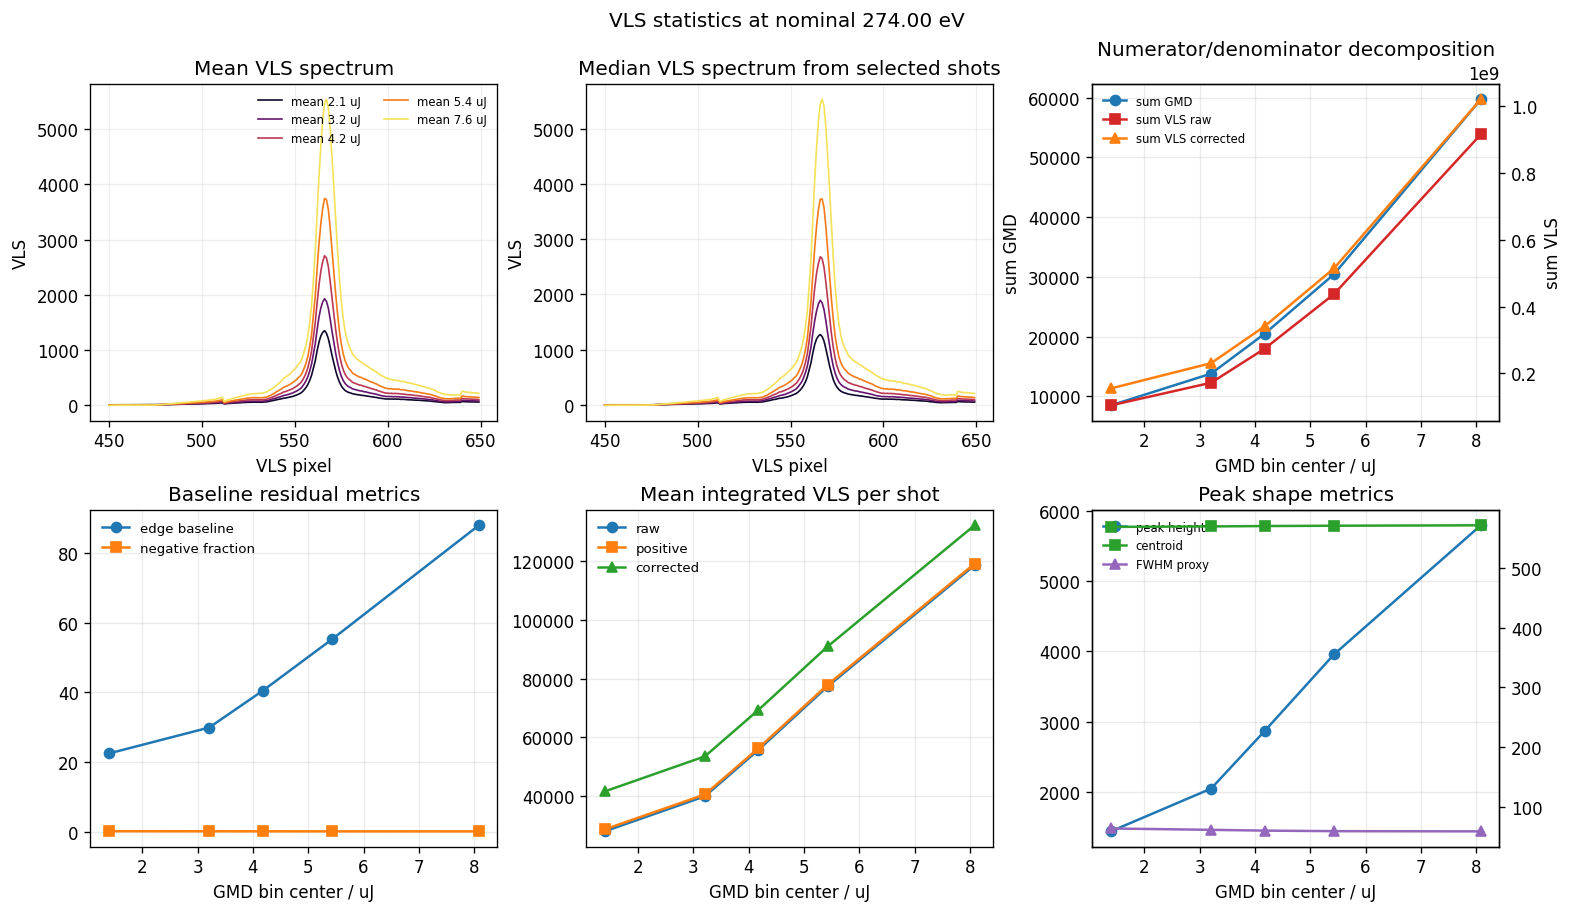

Interpretation metrics near nominal 274.00 eV
metric                         range/span
raw OD span                    0.0996728
corrected OD span              0.0383694
edge baseline span             65.5407
centroid span                  2.69549
FWHM proxy span                4.83516
mean GMD span                  5.45199
mean VLS raw span              90842



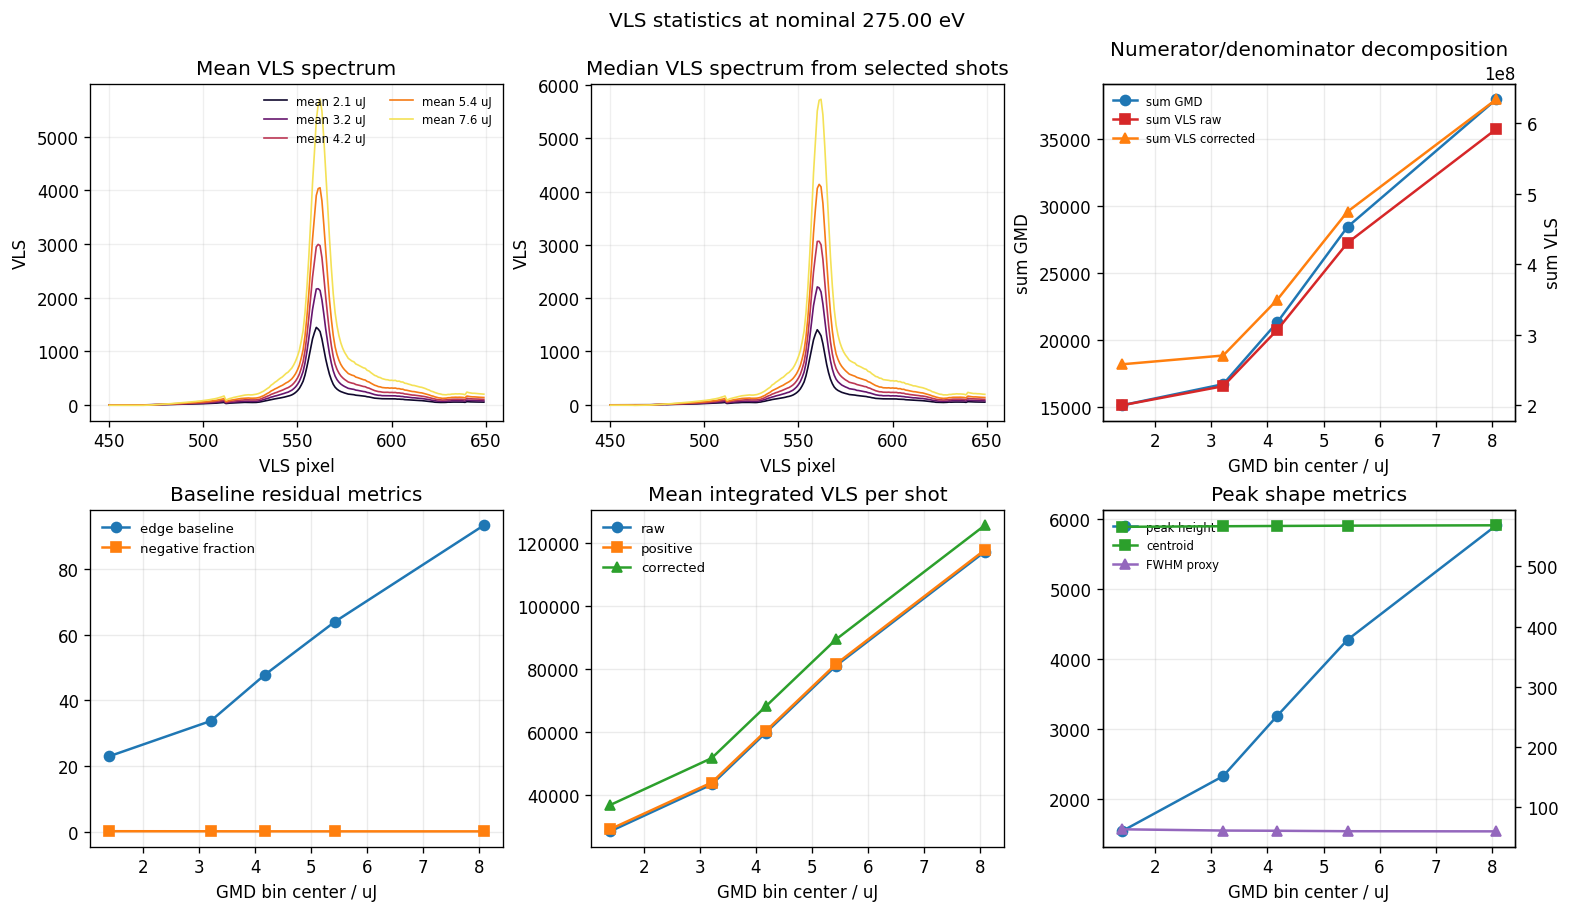

Interpretation metrics near nominal 275.00 eV
metric                         range/span
raw OD span                    0.0723325
corrected OD span              0.0226942
edge baseline span             70.3857
centroid span                  2.54315
FWHM proxy span                3.42155
mean GMD span                  5.35979
mean VLS raw span              88765.5



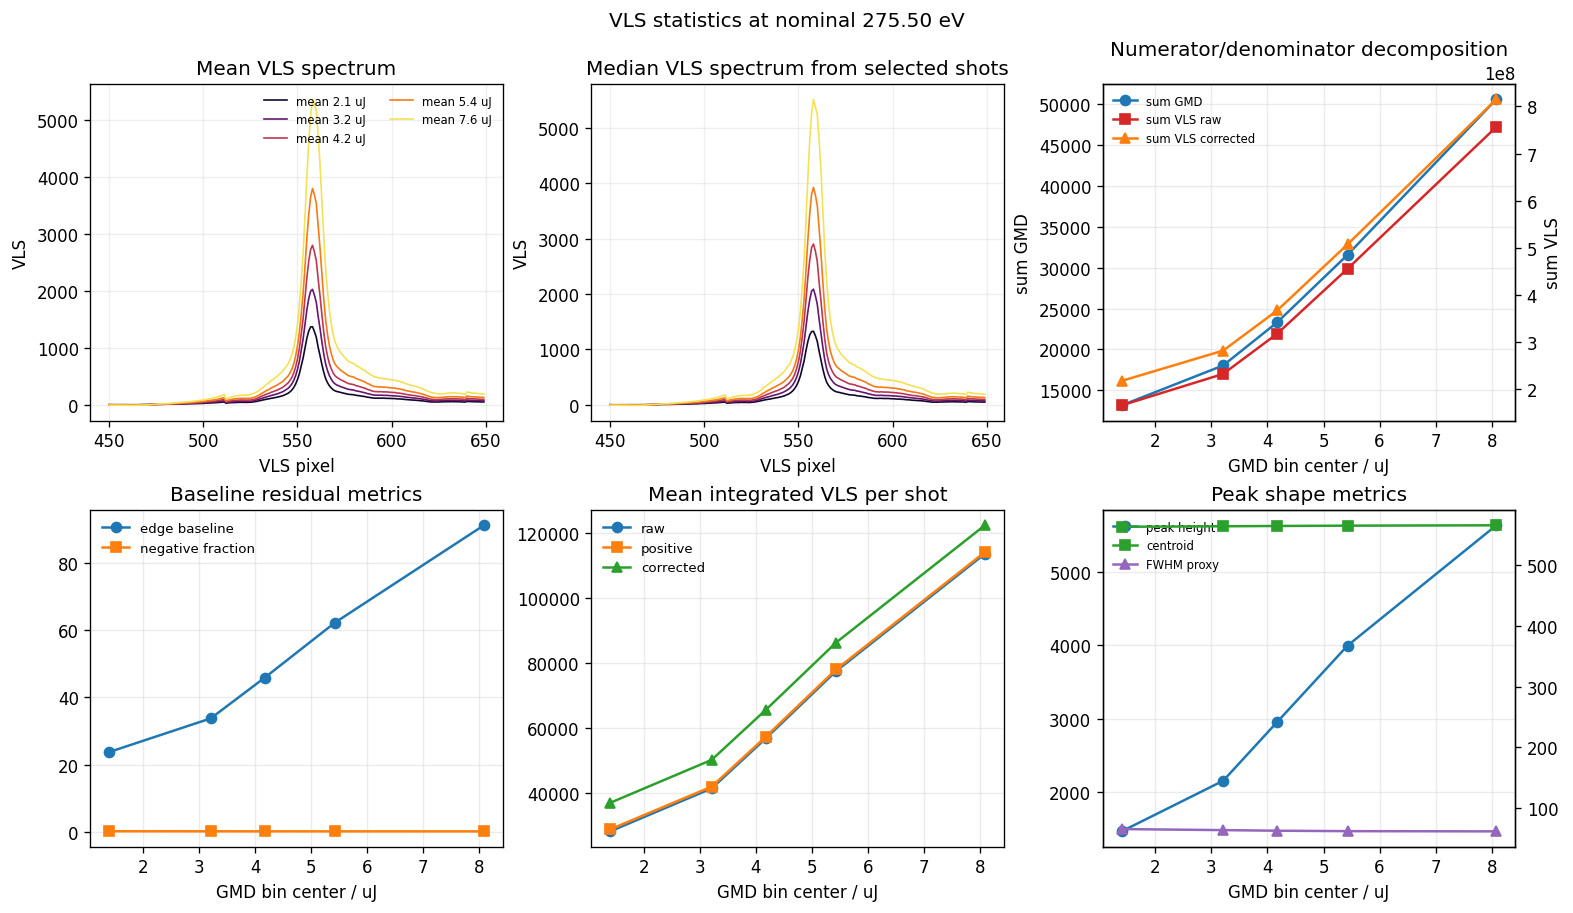

Interpretation metrics near nominal 275.50 eV
metric                         range/span
raw OD span                    0.0725053
corrected OD span              0.0252027
edge baseline span             67.5377
centroid span                  2.40413
FWHM proxy span                3.77213
mean GMD span                  5.37943
mean VLS raw span              85517.1



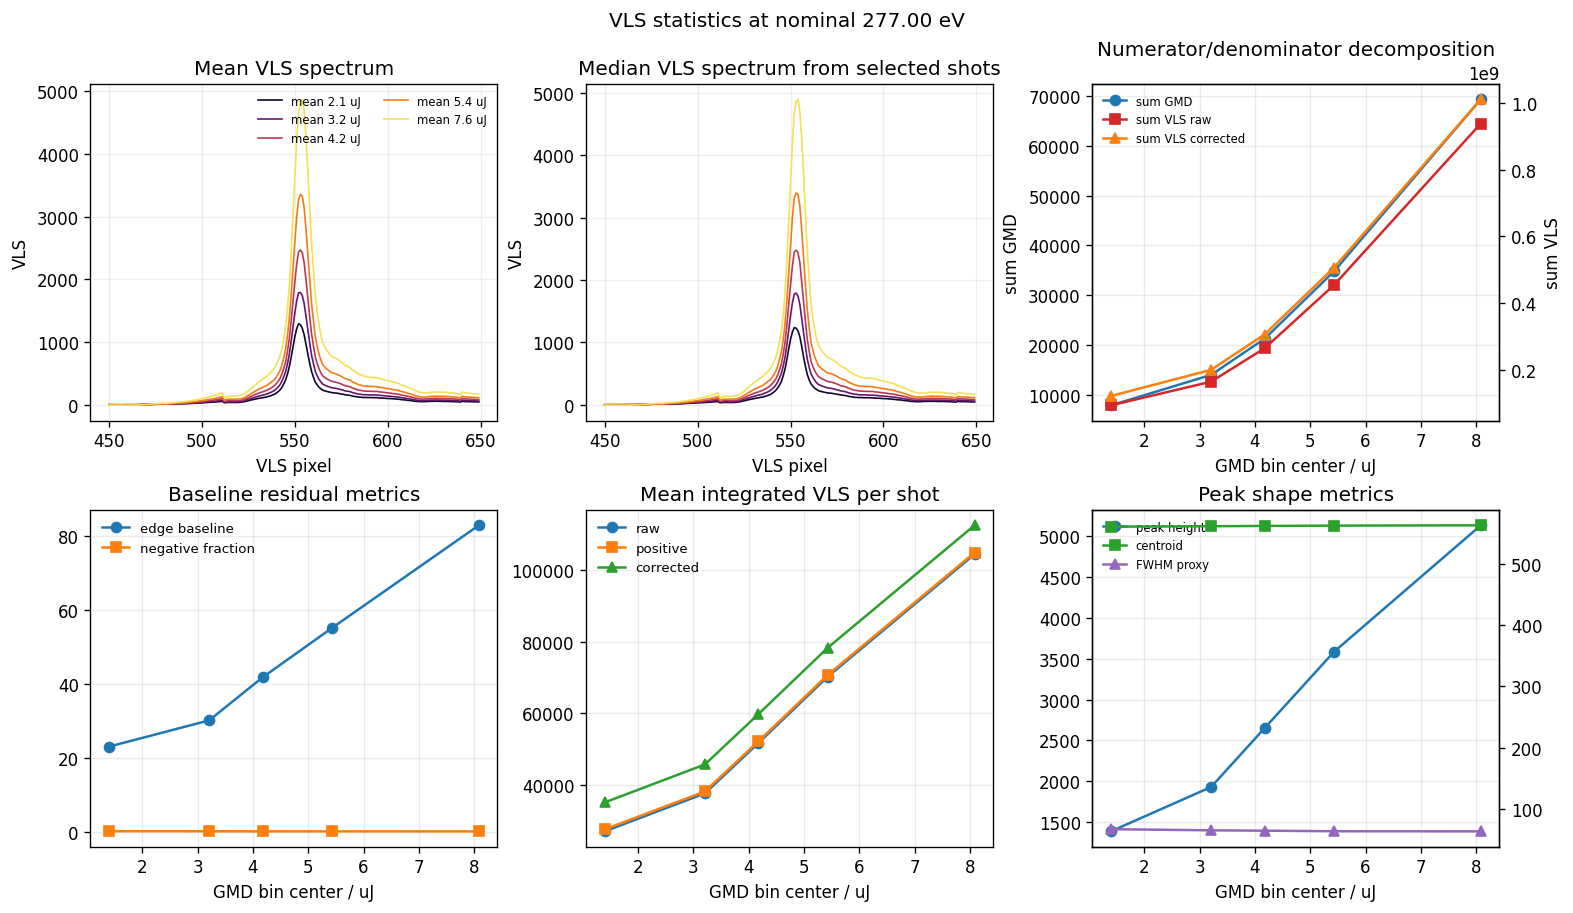

Interpretation metrics near nominal 277.00 eV
metric                         range/span
raw OD span                    0.0649167
corrected OD span              0.02996
edge baseline span             59.8417
centroid span                  2.17902
FWHM proxy span                3.54617
mean GMD span                  5.4093
mean VLS raw span              77553



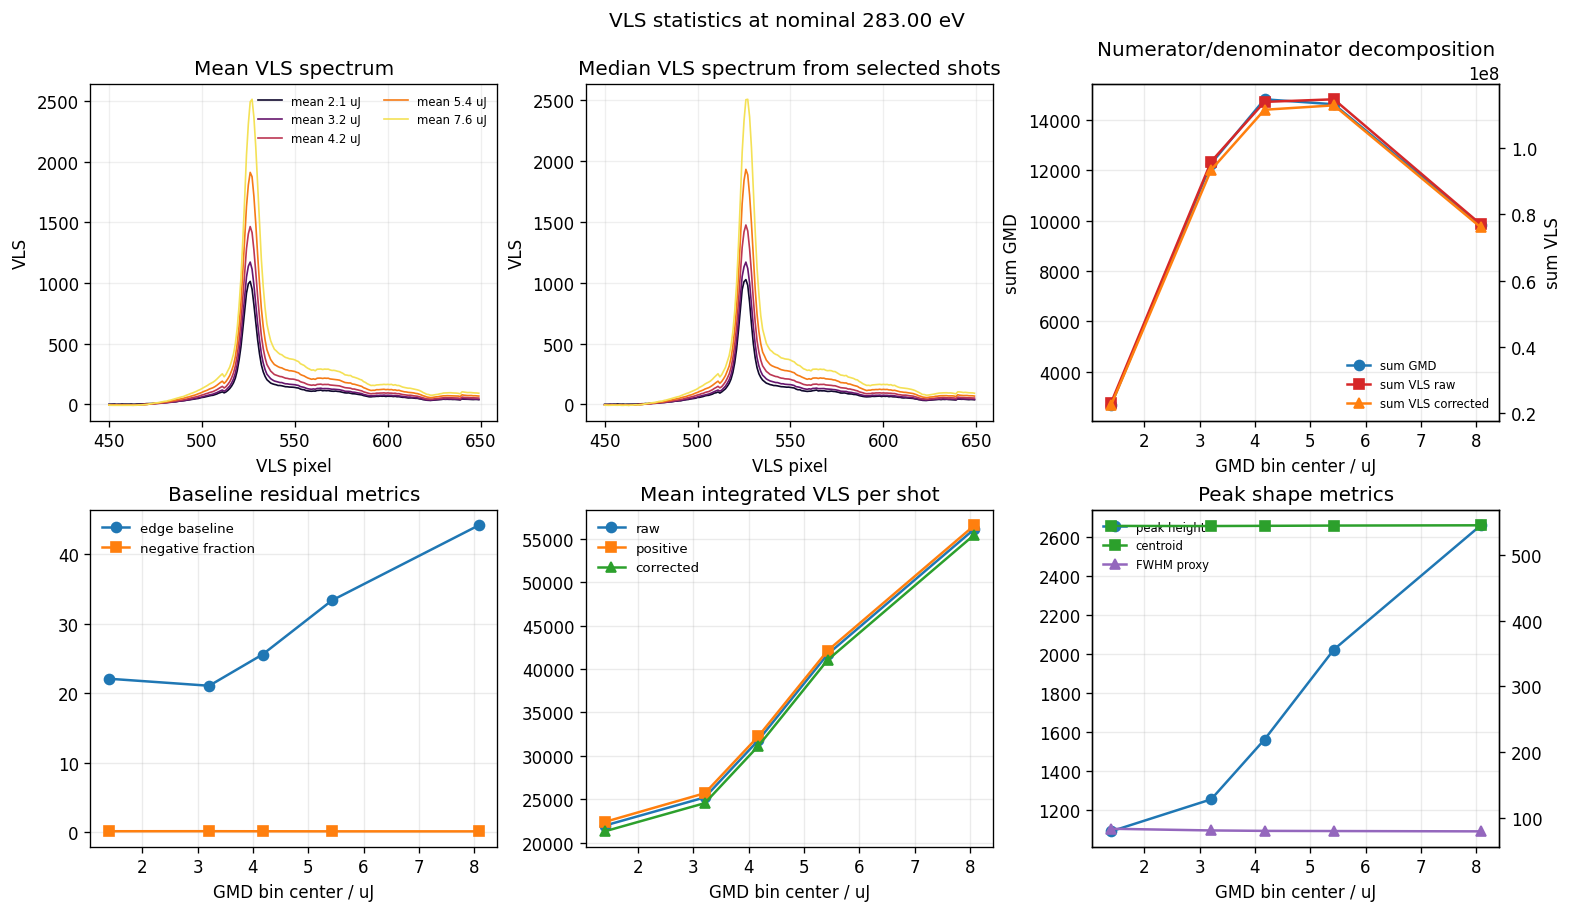

Interpretation metrics near nominal 283.00 eV
metric                         range/span
raw OD span                    0.0505562
corrected OD span              0.046398
edge baseline span             23.1049
centroid span                  1.10912
FWHM proxy span                3.95295
mean GMD span                  4.63203
mean VLS raw span              34198.9



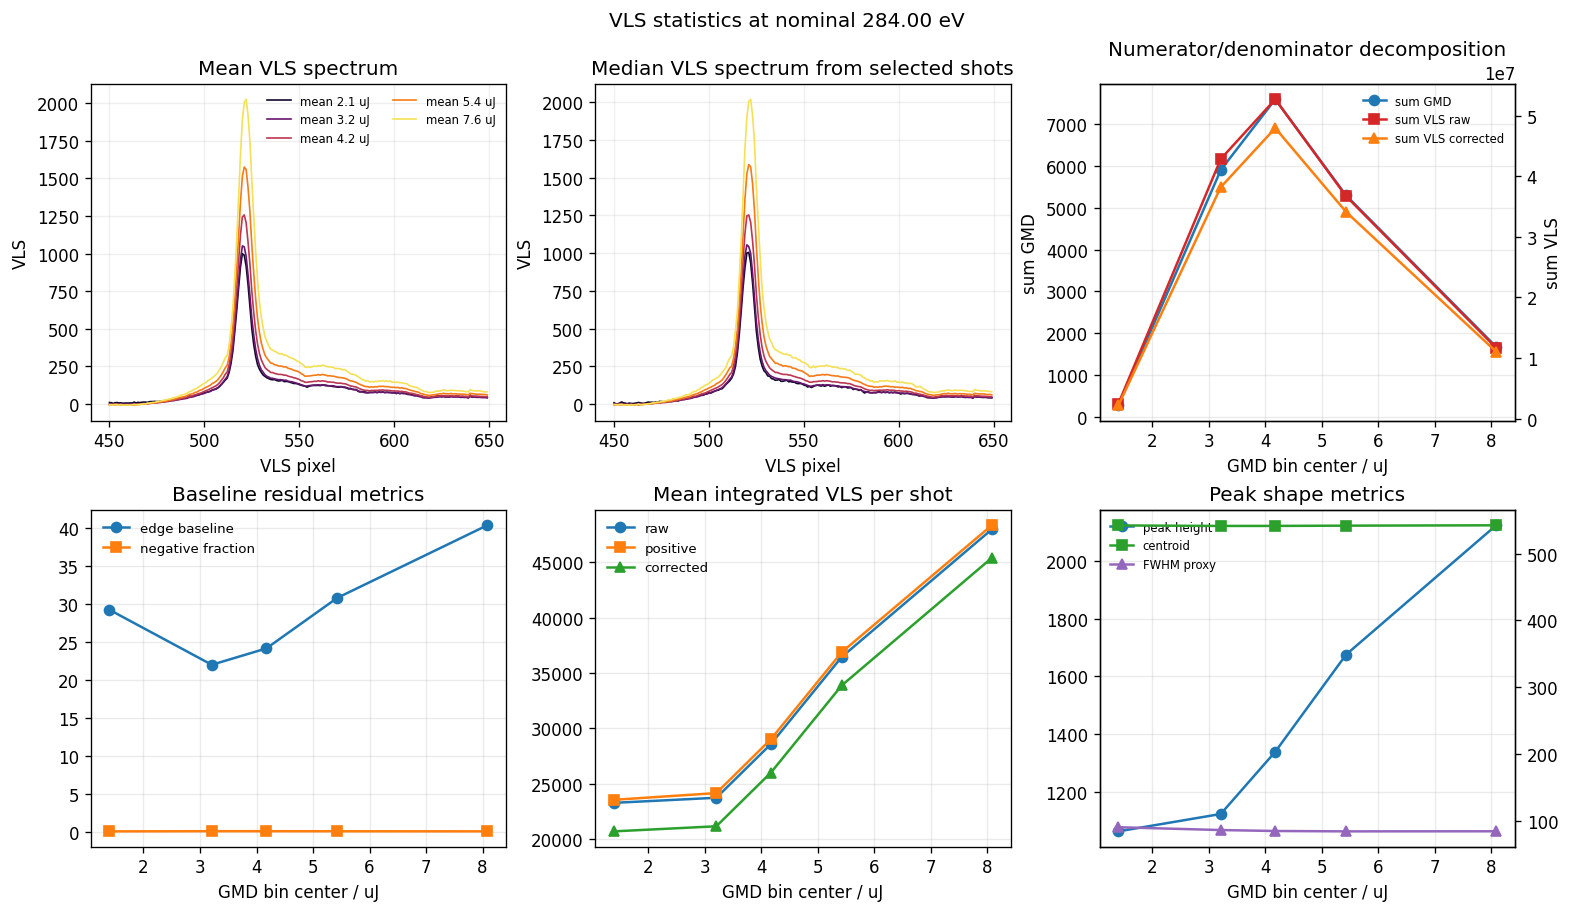

Interpretation metrics near nominal 284.00 eV
metric                         range/span
raw OD span                    0.115896
corrected OD span              0.105538
edge baseline span             18.3732
centroid span                  0.964016
FWHM proxy span                6.17253
mean GMD span                  4.30736
mean VLS raw span              24702.5
Low-stat bins (<200 shots): ['mean 2.1 uJ']



In [9]:
for energy_ev in VLS_STAT_ENERGIES_EV:
    txd.plot_vls_stats_at_energy(
        diag,
        energy_ev,
        corrected=False,
        pixel_xlim=PIXEL_XLIM,
        spectrum_ylim=SPECTRUM_YLIM,
    )
    plt.show()
    txd.print_interpretation_table(diag, energy_ev)
    print()

## 6. Thesis V.10/V.11 Equivalent: Spectral Shape Binning

COM and FWHM binning checks whether different GMD bins also select different FEL spectral shapes.

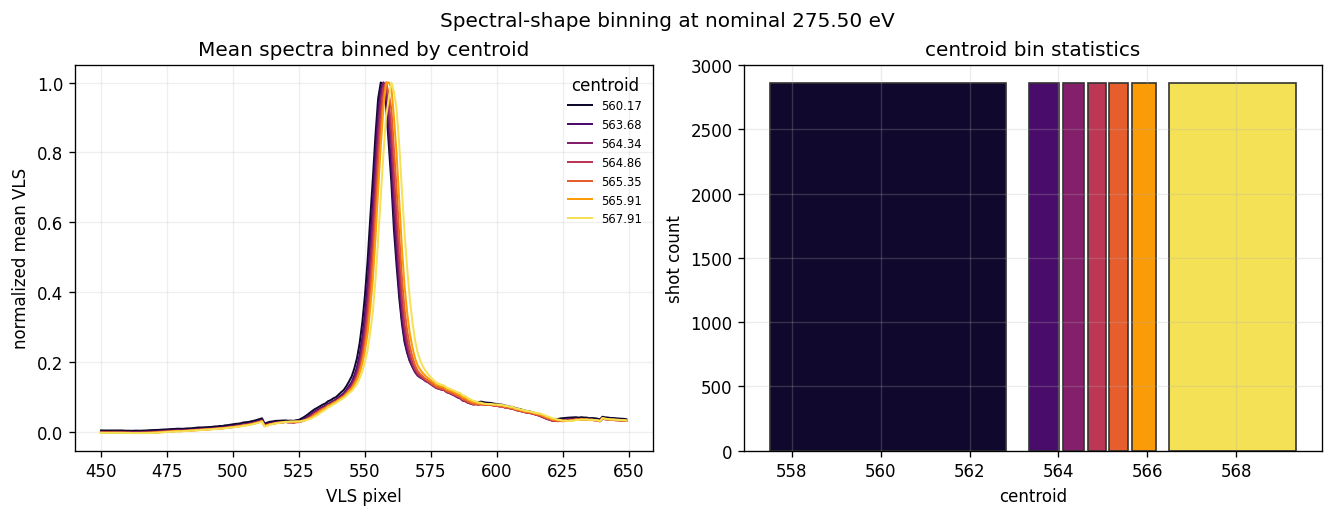

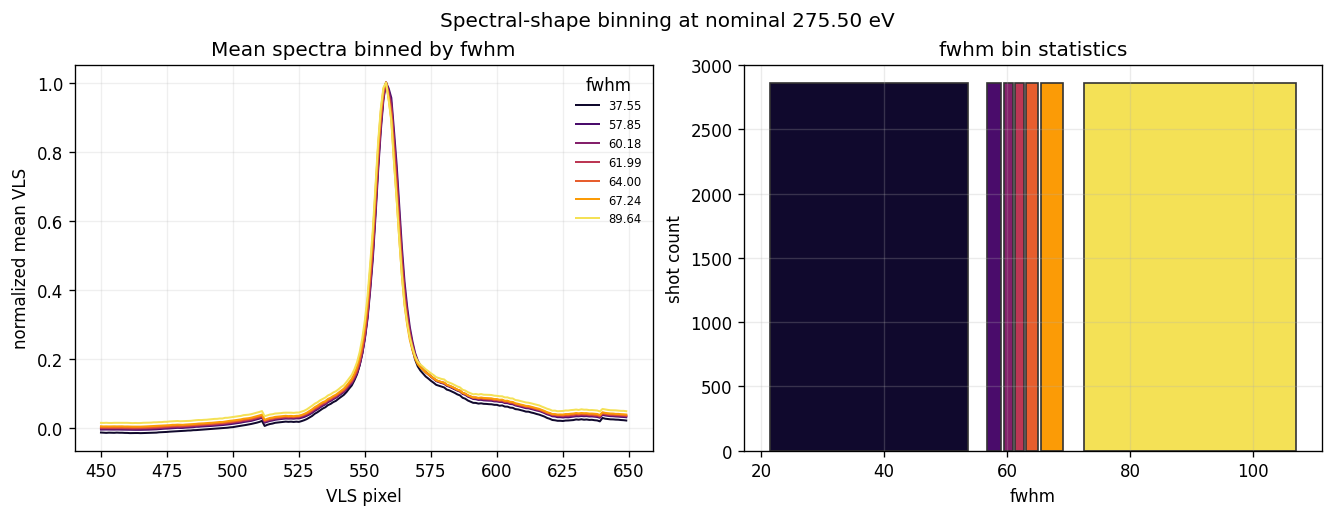

In [10]:
txd.plot_shape_binning(diag, SHAPE_BIN_ENERGY_EV, by="centroid", corrected=False, pixel_xlim=PIXEL_XLIM)
plt.show()

txd.plot_shape_binning(diag, SHAPE_BIN_ENERGY_EV, by="fwhm", corrected=False, pixel_xlim=PIXEL_XLIM)
plt.show()

## 7. Optional: VLS Double-Peak Proxy

This is a frequency-domain multi-peak proxy only.  It is not a strict proof of FEL single-spike lasing.

In [11]:
RUN_DOUBLE_PEAK_SUMMARY = False
DOUBLE_PEAK_MAX_SHOTS_PER_ENERGY = 20_000

if RUN_DOUBLE_PEAK_SUMMARY:
    double_peak_summary = txd.compute_double_peak_summary(
        INPUT_H5,
        CONFIG,
        diag.gmd_edges,
        max_shots_per_energy=DOUBLE_PEAK_MAX_SHOTS_PER_ENERGY,
    )
    txd.plot_double_peak_summary(double_peak_summary, diag.gmd_labels, xlim=FULL_XLIM)
    plt.show()

## Reading Guide

- If `GMD vs VLS` has a non-zero intercept, treat GMD-bin baseline splitting as detector/background-sensitive first.
- If intercept-corrected OD removes the vertical GMD-bin offset while COM/FWHM stay stable, prefer detector/background residual.
- If COM/FWHM changes with GMD, the GMD bins are also sorting FEL spectral shape; compare only matched spectral-shape subsets before claiming fluence physics.
- If OD ordering survives intercept correction and spectral-shape checks, then fluence-dependent physics becomes more plausible.